In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from scipy import stats

In [2]:
con = duckdb.connect("tracking_analysis.duckdb")

TRK_FILE = 'track_amazon_lluc/tracking_table/monthly/*.parquet'

con.execute(
    f"""
    CREATE OR REPLACE VIEW TRACK_TABLE AS
    SELECT uid, timestamp, size
    FROM read_parquet('track_amazon_lluc/tracking_table/monthly/*.parquet')
    """
)

monthly_size = con.execute("""
    SELECT
        MAKE_DATE(YEAR(timestamp), MONTH(timestamp), 1) AS timestamp,
        AVG(size) AS monthly_size
    FROM TRACK_TABLE
    WHERE uid IS NOT NULL
      -- AND timestamp IS NOT NULL
      AND timestamp >= TIMESTAMP '2001-01-01'
      AND size IS NOT NULL
    GROUP BY
        YEAR(timestamp),
        MONTH(timestamp)
    ORDER BY timestamp
""").fetchdf()

In [3]:
monthly_size["timestamp"] = pd.to_datetime(monthly_size["timestamp"])
monthly_size = (monthly_size.set_index("timestamp").sort_index())
monthly_size["eff_rad"] = np.sqrt((monthly_size["monthly_size"] * 100) / np.pi)
monthly_size

,monthly_size,eff_rad
timestamp,,
2001-01-01,68.115858,46.563882
2001-02-01,61.527287,44.254654
2001-03-01,67.426551,46.327678
2001-04-01,59.509994,43.523120
2001-05-01,62.286577,44.526883
...,...,...
2024-08-01,63.589947,44.990342
2024-09-01,62.880087,44.738522
2024-10-01,63.355471,44.907319


In [4]:
series = monthly_size["eff_rad"].astype(float)

result = STL(series, period=13, robust=True).fit()

# Extract components
observed = result.observed
seasonal = result.seasonal
trend = result.trend
residual = result.resid

# Remove the seasonal component
deseasonalized = observed - seasonal

# Linear regression on deseasonalized data
# Convert time to years since the beginning of the record.
x_years = ((deseasonalized.index - deseasonalized.index[0]).days/ 365.25)

X = sm.add_constant(x_years)

model = sm.OLS(deseasonalized.to_numpy(), X).fit(cov_type="HAC", cov_kwds={"maxlags": 12})

linear_fit = model.predict(X)

slope_per_year = model.params[1]
p_value = model.pvalues[1]
r_squared = model.rsquared


print("\nLinear trend in monthly convective-system count")
print(f"Slope:       {slope_per_year:.4f} km/year")
print(f"Slope:       {slope_per_year * 10:.4f} km/decade")
print(f"HAC p-value: {p_value:.4g}")
print(f"R²:          {r_squared:.3f}")


Linear trend in monthly convective-system count
Slope:       0.1265 km/year
Slope:       1.2653 km/decade
HAC p-value: 9.023e-20
R²:          0.286


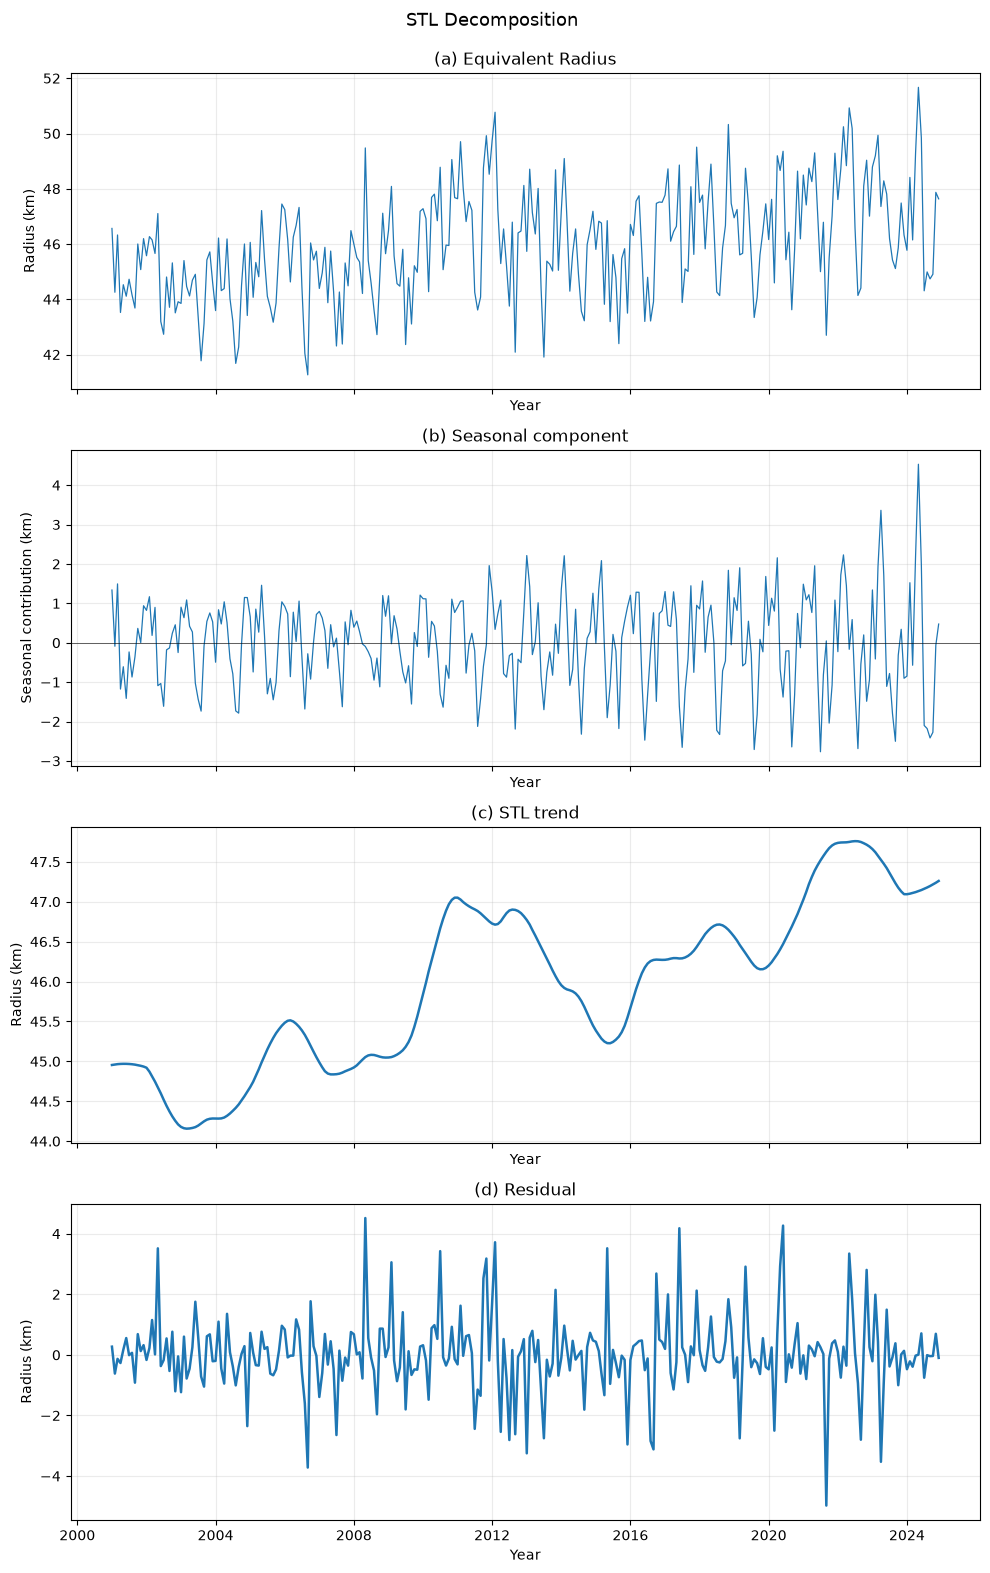

In [5]:
# 
fig, axes = plt.subplots(4, 1, figsize=(10, 16), sharex=True)

# Panel 1: Observed monthly duration statistic
axes[0].plot(observed.index, observed, linewidth=0.9)
axes[0].set_title("(a) Equivalent Radius")
axes[0].set_ylabel("Radius (km)")

# Panel 2: Seasonal component
axes[1].plot(seasonal.index, seasonal, linewidth=0.9)
axes[1].axhline(0, color="black", linewidth=0.7, alpha=0.6)
axes[1].set_title("(b) Seasonal component")
axes[1].set_ylabel("Seasonal contribution (km)")

# Panel 3: STL trend
axes[2].plot(trend.index, trend, linewidth=1.8)
axes[2].set_title("(c) STL trend")
axes[2].set_ylabel("Radius (km)")

# Panel 4: STL trend
axes[3].plot(residual.index, residual, linewidth=1.8)
axes[3].set_title("(d) Residual")
axes[3].set_ylabel("Radius (km)")

for ax in axes:
    ax.set_xlabel("Year")
    ax.grid(alpha=0.25)

fig.suptitle(f"STL Decomposition \n", fontsize=13)

plt.tight_layout()
plt.show()


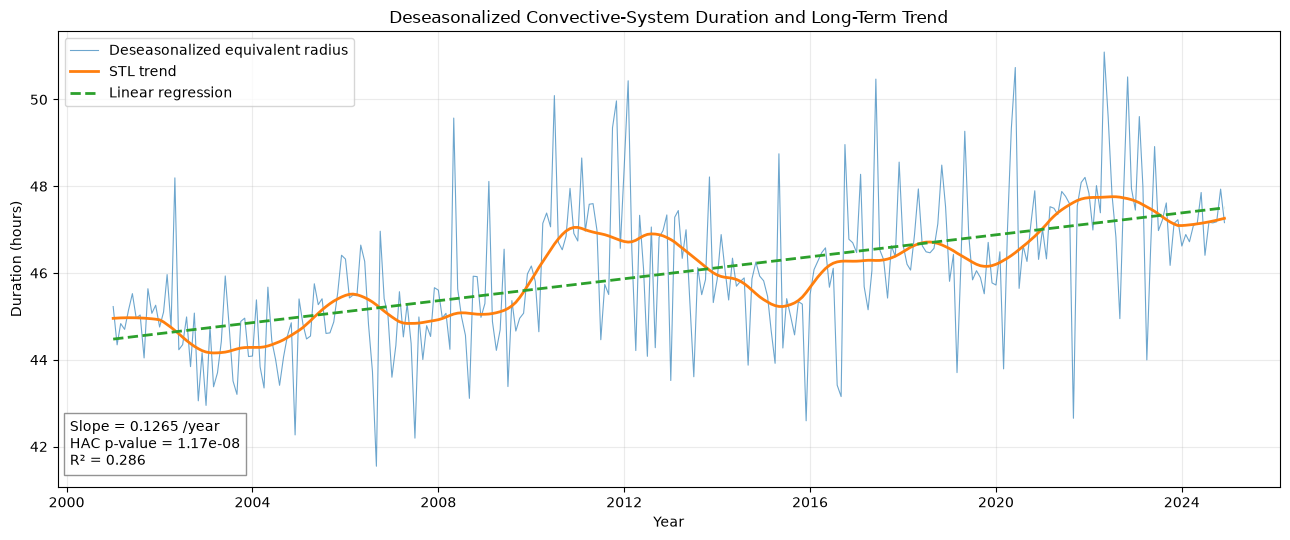

In [21]:
# Deseasonalized data, STL trend, linear fit
fig, ax = plt.subplots(figsize=(13, 5.5))

ax.plot(observed.index, deseasonalized, linewidth=0.8, alpha=0.65, label="Deseasonalized equivalent radius")
ax.plot(trend.index, trend, linewidth=2, label="STL trend")
ax.plot(deseasonalized.index, linear_fit, linestyle="--", linewidth=2, label="Linear regression")

ax.set_title("Deseasonalized Convective-System Duration and Long-Term Trend")
ax.set_xlabel("Year")
ax.set_ylabel("Duration (hours)")
ax.grid(alpha=0.25)
ax.legend()

annotation = (f"Slope = {slope_per_year:.4f} /year\n" f"HAC p-value = {p_value:.3g}\n" f"R² = {r_squared:.3f}")
ax.text(0.01, 0.15, annotation, transform=ax.transAxes, va="top", ha="left", bbox=dict(facecolor="white", alpha=0.85, edgecolor="gray"))

plt.tight_layout()
plt.show()

In [8]:
# Examine the annual amplitude from the seasonal component
# Combine into a DataFrame and extract the year
df = pd.DataFrame({'seasonal': seasonal})
df['year'] = df.index.year

# Group by year and find the annual peak (max) and valley (min)
annual_extrema = df.groupby('year')['seasonal'].agg(peak='max', valley='min')
# Compute the annual amplitude (Peak - Valley)
annual_extrema['amplitude'] = annual_extrema['peak'] - annual_extrema['valley']
annual_extrema

,peak,valley,amplitude
year,,,
2001,1.493720,-1.412882,2.906603
2002,1.168488,-1.613467,2.781954
2003,1.086582,-1.736242,2.822824
2004,1.148966,-1.787342,2.936308
2005,1.459054,-1.448790,2.907844
2006,1.057284,-1.682630,2.739914
2007,0.823408,-1.625059,2.448467
2008,1.198652,-1.119701,2.318353
2009,1.209261,-1.555969,2.765230


In [26]:
# Simple Ordinary Least Squares (OLS) regression on the amplitude trend
years = annual_extrema.index.values
amplitudes = annual_extrema['amplitude'].values
slope, intercept, r_value, p_value, std_err = stats.linregress(years, amplitudes)
print(f"Trend Slope: {slope:.4f} per year")
print(f"P-value: {p_value:.4f}")
if p_value < 0.05:
    print("Statistically significant trend in seasonal amplitude.")
else:
    print("No statistically significant trend in amplitude.")

Trend Slope: 0.1443 per year
P-value: 0.0000
Statistically significant trend in seasonal amplitude.


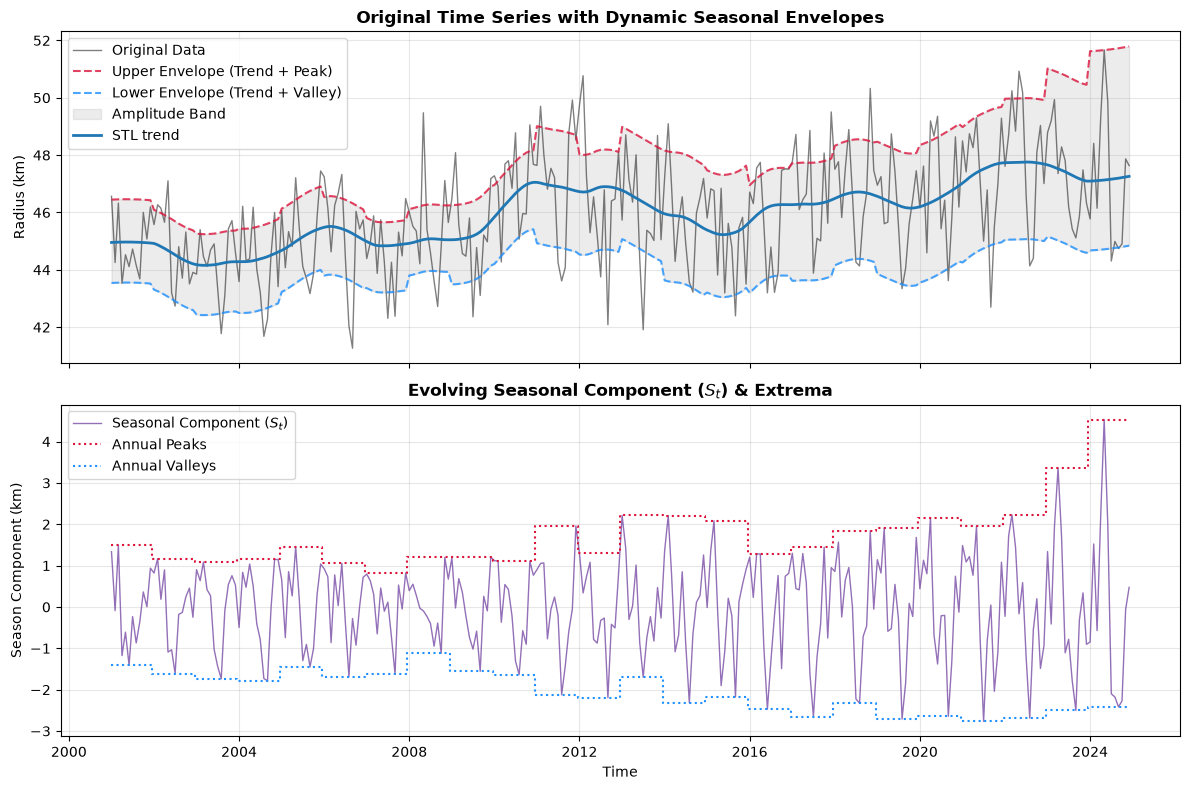

In [28]:
# Assuming you already have:
# - df: DataFrame with DatetimeIndex containing columns ['original', 'trend', 'seasonal']
# - annual_extrema: DataFrame from the previous step containing ['peak', 'valley'] indexed by year

# 1. Map the annual peaks and valleys back to the main DataFrame timeline
df['trend'] = trend
df['year'] = df.index.year
df['seasonal_peak'] = df['year'].map(annual_extrema['peak'])
df['seasonal_valley'] = df['year'].map(annual_extrema['valley'])

# 2. Calculate total envelopes (Trend + Seasonal Extrema)
df['upper_envelope'] = df['trend'] + df['seasonal_peak']
df['lower_envelope'] = df['trend'] + df['seasonal_valley']

# 3. Create the multi-panel plot
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# --- Top Panel: Original Data with Envelopes ---
axes[0].plot(df.index, observed, label='Original Data', color='black', alpha=0.5, linewidth=1)
axes[0].plot(df.index, df['upper_envelope'], label='Upper Envelope (Trend + Peak)', color='crimson', linestyle='--', alpha=0.8)
axes[0].plot(df.index, df['lower_envelope'], label='Lower Envelope (Trend + Valley)', color='dodgerblue', linestyle='--', alpha=0.8)
axes[0].fill_between(df.index, df['lower_envelope'], df['upper_envelope'], color='gray', alpha=0.15, label='Amplitude Band')
axes[0].plot(trend.index, trend, linewidth=2, label="STL trend")
axes[0].set_title('Original Time Series with Dynamic Seasonal Envelopes', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper left', frameon=True)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylabel('Radius (km)', fontsize = 10)

# --- Bottom Panel: Isolated Seasonal Component ---
axes[1].plot(df.index, df['seasonal'], label='Seasonal Component ($S_t$)', color='rebeccapurple', alpha=0.7, linewidth=1)
axes[1].plot(df.index, df['seasonal_peak'], label='Annual Peaks', color='crimson', linestyle=':', drawstyle='steps-mid', linewidth=1.5)
axes[1].plot(df.index, df['seasonal_valley'], label='Annual Valleys', color='dodgerblue', linestyle=':', drawstyle='steps-mid', linewidth=1.5)
axes[1].set_title('Evolving Seasonal Component ($S_t$) & Extrema', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper left', frameon=True)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylabel('Season Component (km)', fontsize = 10)

# Layout adjustments
plt.xlabel('Time', fontsize=10)
plt.tight_layout()
plt.show()

In [27]:
# Assuming annual_extrema is your DataFrame indexed by year with columns ['peak', 'valley']
years = annual_extrema.index.values
# Trend analysis for the Peaks
slope_peak, intercept_peak, r_peak, p_peak, se_peak = stats.linregress(years, annual_extrema['peak'])
# Trend analysis for the Valleys
slope_valley, intercept_valley, r_valley, p_valley, se_valley = stats.linregress(years, annual_extrema['valley'])

print(f"Peaks Trend:   Slope = {slope_peak:+.4f} per year (p = {p_peak:.4f})")
print(f"Valleys Trend: Slope = {slope_valley:+.4f} per year (p = {p_valley:.4f})")

Peaks Trend:   Slope = +0.0840 per year (p = 0.0001)
Valleys Trend: Slope = -0.0603 per year (p = 0.0000)


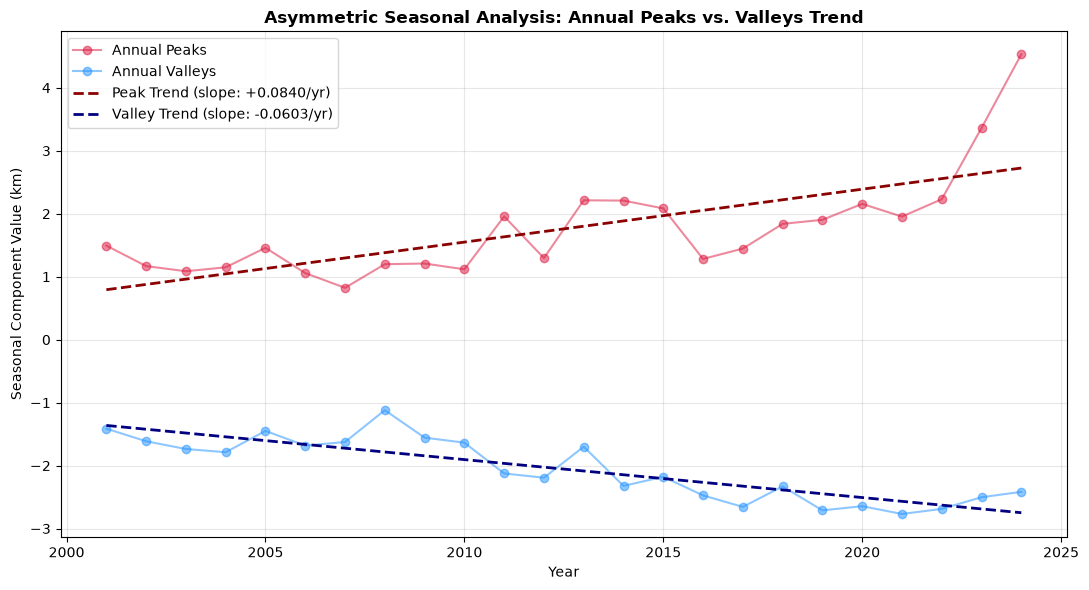

In [29]:
# Assuming annual_extrema is your DataFrame indexed by 'year' with columns ['peak', 'valley']
years = annual_extrema.index.values
peaks = annual_extrema['peak'].values
valleys = annual_extrema['valley'].values

# 1. Calculate OLS regressions for peaks and valleys
slope_peak, intercept_peak, _, _, _ = stats.linregress(years, peaks)
slope_valley, intercept_valley, _, _, _ = stats.linregress(years, valleys)

# Generate trendline values
peak_trend = intercept_peak + slope_peak * years
valley_trend = intercept_valley + slope_valley * years

# 2. Plotting the data
plt.figure(figsize=(11, 6))

# Plot raw annual extrema
plt.plot(years, peaks, marker='o', color='crimson', linestyle='-', alpha=0.5, label='Annual Peaks')
plt.plot(years, valleys, marker='o', color='dodgerblue', linestyle='-', alpha=0.5, label='Annual Valleys')

# Plot individual OLS trendlines
plt.plot(years, peak_trend, color='darkred', linestyle='--', linewidth=2, label=f'Peak Trend (slope: {slope_peak:+.4f}/yr)')
plt.plot(years, valley_trend, color='navy', linestyle='--', linewidth=2, label=f'Valley Trend (slope: {slope_valley:+.4f}/yr)')

# 3. Chart styling and labels
plt.title('Asymmetric Seasonal Analysis: Annual Peaks vs. Valleys Trend', fontsize=12, fontweight='bold')
plt.xlabel('Year', fontsize=10)
plt.ylabel('Seasonal Component Value (km)', fontsize=10)
plt.legend(frameon=True, loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()